# Project Part 3 - Distributions
Statistical and Quantitative Methods for Finance

## Part III - Central Limit Theorem

## Question 1 - Uniform samples
I generated random numbers between -50 and 50 using the sample sizes from the question.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, lognorm

np.random.seed(42)
N_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 20]

for N in N_values:
    sample = np.random.uniform(-50, 50, size=N)
    print("N =", N, "Sample =", sample)

N = 2 Sample = [-12.54598812  45.07143064]
N = 3 Sample = [ 23.19939418   9.86584842 -34.39813596]
N = 4 Sample = [-34.40054797 -44.19163878  36.61761458  10.11150117]
N = 5 Sample = [ 20.80725778 -47.94155057  46.99098522  33.24426408 -28.76608893]
N = 6 Sample = [-31.81750328 -31.65954901 -19.5757757    2.47564316  -6.80549814
 -20.87708598]
N = 7 Sample = [ 11.18528947 -36.05061393 -20.78553515 -13.36381567  -4.39300158
  28.51759614 -30.03262178]
N = 8 Sample = [  1.42344384   9.24145689 -45.35495873  10.75448519 -32.94758763
 -43.4948407   44.88855373  46.56320331]
N = 9 Sample = [ 30.83973481 -19.53862308 -40.2327886   18.42330265  -5.98475063
 -37.79617652  -0.48230899 -46.56114789  40.93204021]
N = 10 Sample = [-24.12200184  16.25222844 -18.82889239   2.00680212   4.67102793
 -31.51455445  46.95846278  27.51328234  43.94989416  39.48273504]
N = 20 Sample = [  9.78999788  42.1874235  -41.15074979 -30.40171376 -45.47727111
 -17.46696692 -11.13227103 -22.86509682  32.87375092 -14.

## Question 2 - Sample mean
I used np.mean to find the average of the sample.

In [2]:
sample_mean = np.mean(sample)
print("Sample mean:", round(sample_mean, 3))

Sample mean: -6.798


## Question 3 - 100,000 trials
I repeated this 100,000 times for each N and saved the means.

In [3]:
L = 100000
sample_means = {}

for N in N_values:
    samples = np.random.uniform(-50, 50, size=(N, L))
    means = np.mean(samples, axis=0)
    sample_means[N] = means
    print("N =", N, "number of sample means =", len(means))

N = 2 number of sample means = 100000
N = 3 number of sample means = 100000
N = 4 number of sample means = 100000
N = 5 number of sample means = 100000
N = 6 number of sample means = 100000
N = 7 number of sample means = 100000
N = 8 number of sample means = 100000
N = 9 number of sample means = 100000
N = 10 number of sample means = 100000
N = 20 number of sample means = 100000


## Question 4 - Histograms and normal curves

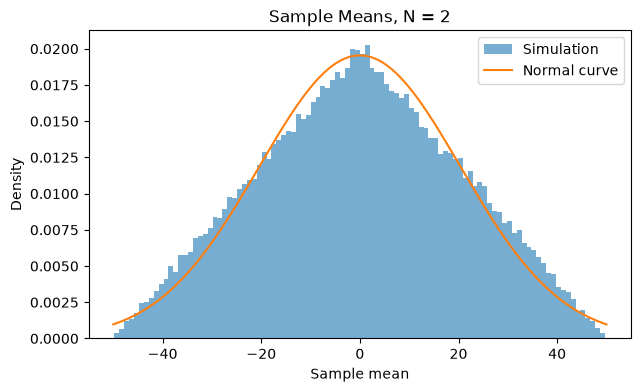

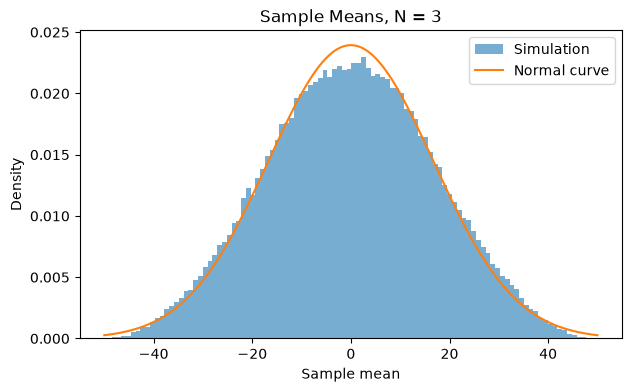

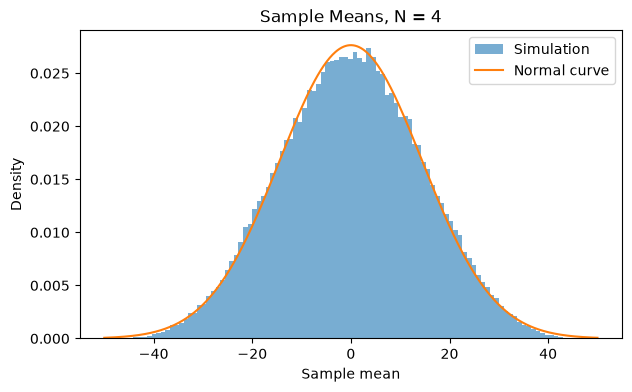

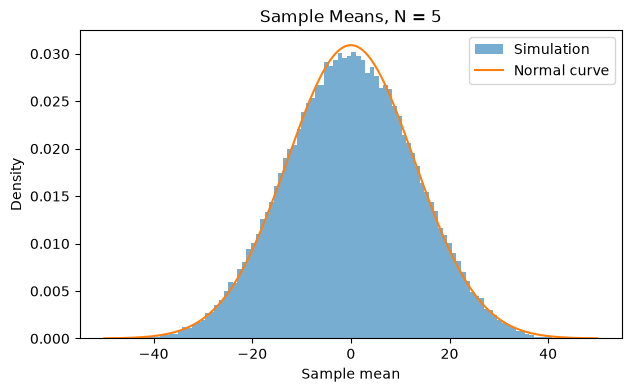

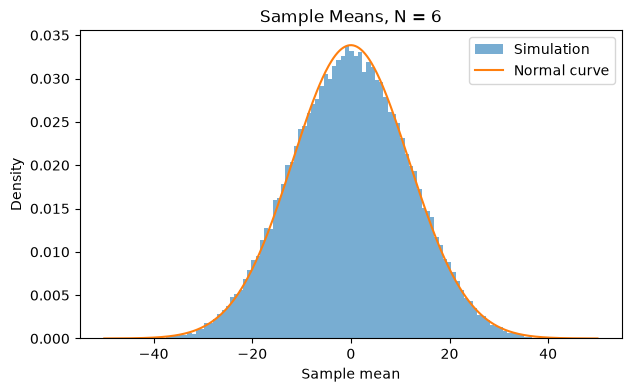

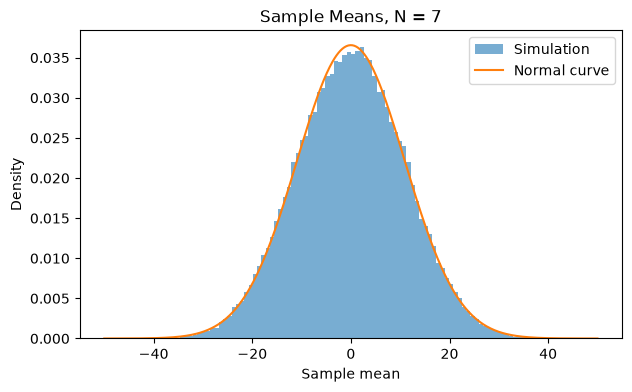

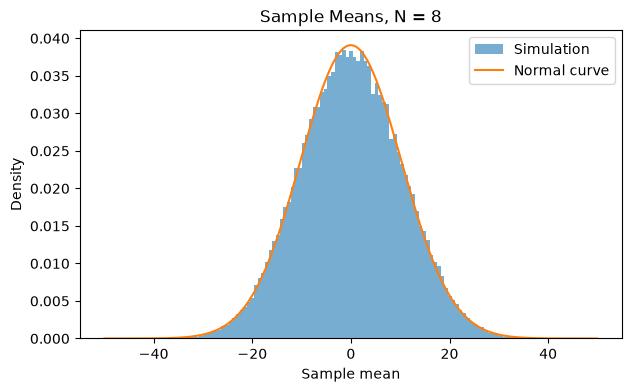

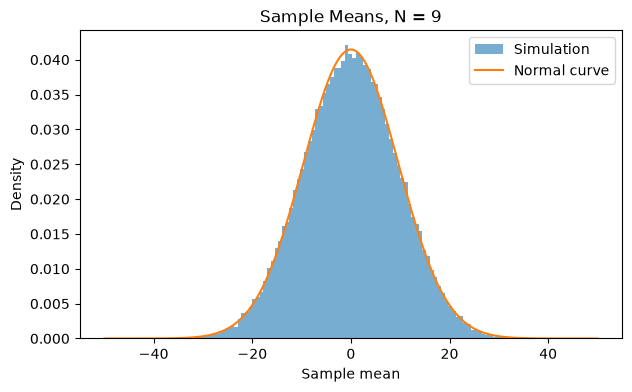

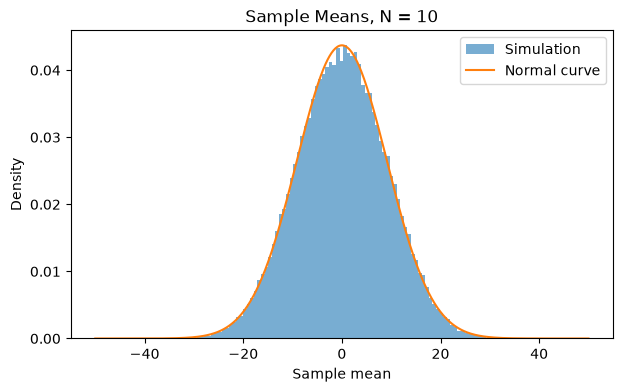

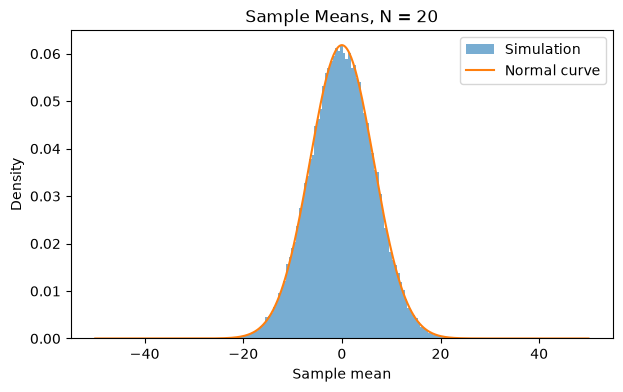

In [4]:
for N in N_values:
    means = sample_means[N]
    variance = 100**2/(12*N)
    sd = np.sqrt(variance)
    x = np.linspace(-50, 50, 500)

    plt.figure(figsize=(7, 4))
    plt.hist(means, bins=100, density=True, alpha=0.6, label='Simulation')
    plt.plot(x, norm.pdf(x, 0, sd), label='Normal curve')
    plt.title('Sample Means, N = ' + str(N))
    plt.xlabel('Sample mean')
    plt.ylabel('Density')
    plt.legend()
    plt.show()

## Question 5
For N = 2, the histogram looks more like a triangle than a normal curve. It starts looking closer as N increases. By N = 10 and 20, the histograms are pretty close to the normal curves. So the CLT works better with larger samples.

## Question 6 - Standard errors

In [5]:
print('N   Simulated SE   Theoretical SE')
for N in N_values:
    sim_se = np.std(sample_means[N], ddof=1)
    theory_se = np.sqrt(100**2/(12*N))
    print(N, ' ', round(sim_se, 4), '       ', round(theory_se, 4))

N   Simulated SE   Theoretical SE
2   20.3827         20.4124
3   16.7507         16.6667
4   14.3527         14.4338
5   12.9188         12.9099
6   11.8052         11.7851
7   10.9088         10.9109
8   10.2519         10.2062
9   9.6058         9.6225
10   9.131         9.1287
20   6.472         6.455


The simulated and theoretical standard errors are close. At N = 2, they are about 20.38 and 20.41. At N = 20, they are about 6.47 and 6.45. The standard error gets smaller as N increases.

## Question 7 - 95% intervals
I used 0 plus or minus 1.96 times the standard error to get the bounds. This gives the middle 95% of the sample mean distribution using the normal approximation. Since I already know the population mean is 0, these are not intervals calculated from a single sample.

In [6]:
ci_lower = []
ci_upper = []
for N in N_values:
    se = np.sqrt(100**2/(12*N))
    lower = -1.96*se
    upper = 1.96*se
    ci_lower.append(lower)
    ci_upper.append(upper)
    print('N =', N, '95% interval = (', round(lower, 3), ',', round(upper, 3), ')')

N = 2 95% interval = ( -40.008 , 40.008 )
N = 3 95% interval = ( -32.667 , 32.667 )
N = 4 95% interval = ( -28.29 , 28.29 )
N = 5 95% interval = ( -25.303 , 25.303 )
N = 6 95% interval = ( -23.099 , 23.099 )
N = 7 95% interval = ( -21.385 , 21.385 )
N = 8 95% interval = ( -20.004 , 20.004 )
N = 9 95% interval = ( -18.86 , 18.86 )
N = 10 95% interval = ( -17.892 , 17.892 )
N = 20 95% interval = ( -12.652 , 12.652 )


## Question 8 - Plot the intervals
I plotted the upper and lower bounds against the square root of N.

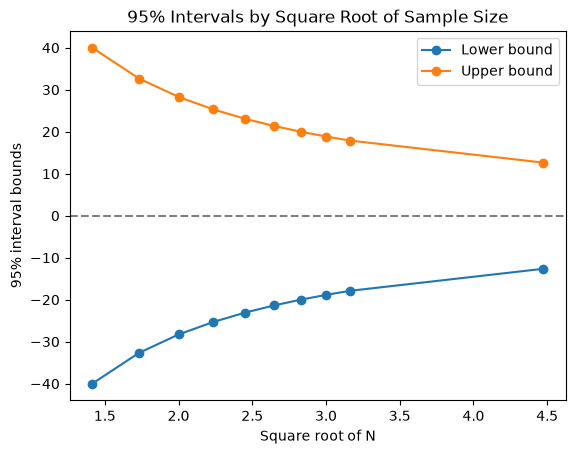

In [7]:
sqrt_N = np.sqrt(N_values)
plt.plot(sqrt_N, ci_lower, marker='o', label='Lower bound')
plt.plot(sqrt_N, ci_upper, marker='o', label='Upper bound')
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Square root of N')
plt.ylabel('95% interval bounds')
plt.title('95% Intervals by Square Root of Sample Size')
plt.legend()
plt.show()

The interval gets narrower for larger sample sizes because the standard error is smaller.

## Monte Carlo
I used a starting price of $100, a 10% annual return, 15% volatility, and 1 million shares.

## Question 9 - 100 simulated price trajectories

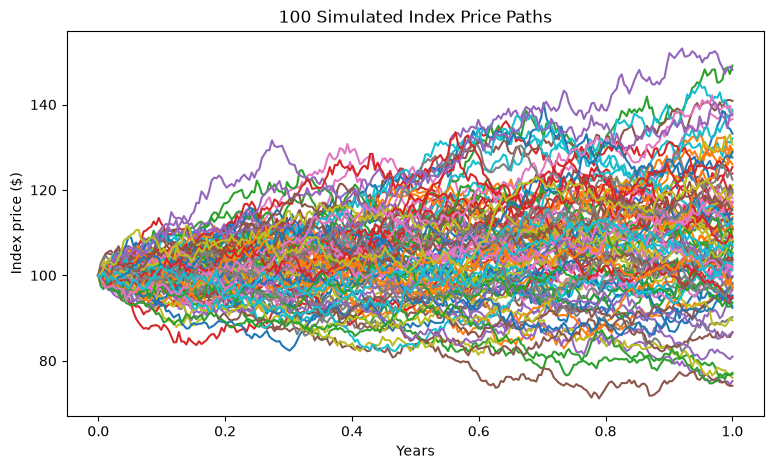

In [8]:
S0 = 100
mu = 0.10
sigma = 0.15
T = 1
n = 252
dt = T/n
L = 100

changes = np.exp((mu - sigma**2/2)*dt + sigma*np.random.normal(0, np.sqrt(dt), size=(n, L)))
prices = np.vstack([np.ones(L), changes])
prices = S0*prices.cumprod(axis=0)

plt.figure(figsize=(9, 5))
plt.plot(np.arange(n+1)/252, prices)
plt.title('100 Simulated Index Price Paths')
plt.xlabel('Years')
plt.ylabel('Index price ($)')
plt.show()

## Question 10 - 100,000 simulations
I ran 100,000 simulations and kept the prices at 6 months and 12 months for the histograms.

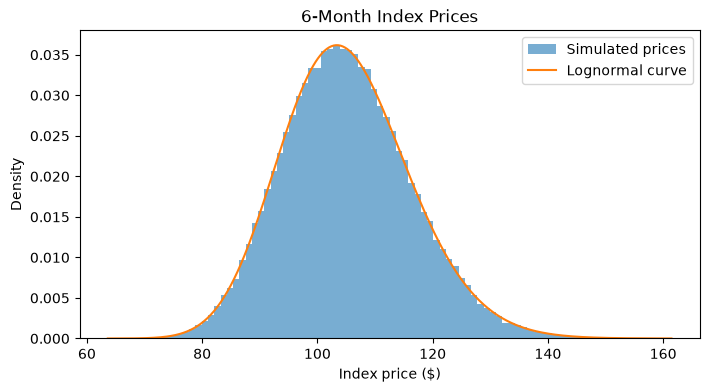

6 months: mean = 105.153 median = 104.598 SD = 11.177 skewness = 0.307


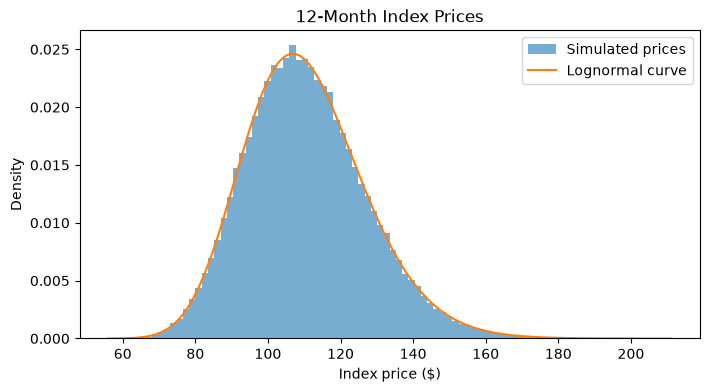

12 months: mean = 110.521 median = 109.308 SD = 16.678 skewness = 0.459


In [9]:
L = 100000
prices_6mo = np.ones(L)*S0
for day in range(126):
    returns = np.random.normal(0, np.sqrt(dt), L)
    prices_6mo = prices_6mo*np.exp((mu-sigma**2/2)*dt + sigma*returns)

prices_12mo = prices_6mo.copy()
for day in range(126):
    returns = np.random.normal(0, np.sqrt(dt), L)
    prices_12mo = prices_12mo*np.exp((mu-sigma**2/2)*dt + sigma*returns)

for months, values in [(6, prices_6mo), (12, prices_12mo)]:
    years = months/12
    x = np.linspace(values.min(), values.max(), 500)
    shape = sigma*np.sqrt(years)
    scale = S0*np.exp((mu-sigma**2/2)*years)
    plt.figure(figsize=(8, 4))
    plt.hist(values, bins=90, density=True, alpha=0.6, label='Simulated prices')
    plt.plot(x, lognorm.pdf(x, s=shape, scale=scale), label='Lognormal curve')
    plt.title(str(months) + '-Month Index Prices')
    plt.xlabel('Index price ($)')
    plt.ylabel('Density')
    plt.legend()
    plt.show()
    print(months, 'months: mean =', round(np.mean(values), 3),
          'median =', round(np.median(values), 3),
          'SD =', round(np.std(values), 3),
          'skewness =', round(np.mean(((values-np.mean(values))/np.std(values))**3), 3))

Both histograms look lognormal. In each one, the mean is a little higher than the median. The 12-month prices are more spread out and have a longer right tail, so they have higher volatility and more skew.

## Question 11 - Loss probabilities
With 1 million shares, losing $25 million means the index price falls below $75. Losing $5 million means it falls below $95.

In [10]:
shares = 1000000
for months, values in [(6, prices_6mo), (12, prices_12mo)]:
    portfolio_loss = (S0-values)*shares
    print(months, 'months')
    for target in [25000000, 5000000]:
        probability = np.mean(portfolio_loss > target)
        print('Probability of losing more than $', target/1000000,
              'million =', round(probability*100, 3), '%')

6 months
Probability of losing more than $ 25.0 million = 0.094 %
Probability of losing more than $ 5.0 million = 18.331 %
12 months
Probability of losing more than $ 25.0 million = 0.641 %
Probability of losing more than $ 5.0 million = 17.551 %


The chance of losing more than $25 million goes from about 0.094% at 6 months to 0.641% at 12 months. For a $5 million loss, it goes from about 18.331% to 17.552%. I thought both would increase with time, but the smaller loss is a little less likely after 12 months. The price has more time to change, but the positive expected return also pushes the average price up.

## Question 12 - Average loss above each cutoff
I selected the simulations where the loss was greater than each cutoff and found the average loss for those cases.

In [11]:
for months, values in [(6, prices_6mo), (12, prices_12mo)]:
    portfolio_loss = (S0-values)*shares
    print(months, 'months')
    for target in [25000000, 5000000]:
        big_losses = portfolio_loss[portfolio_loss > target]
        if len(big_losses) > 0:
            avg_loss = np.mean(big_losses)
            print('Average loss given loss > $', target/1000000,
                  'million = $', round(avg_loss/1000000, 3), 'million',
                  '(events:', len(big_losses), ')')
        else:
            print('No simulated losses above $', target/1000000, 'million')

6 months
Average loss given loss > $ 25.0 million = $ 27.138 million (events: 94 )
Average loss given loss > $ 5.0 million = $ 10.239 million (events: 18331 )
12 months
Average loss given loss > $ 25.0 million = $ 28.363 million (events: 641 )
Average loss given loss > $ 5.0 million = $ 12.187 million (events: 17551 )


For losses above $25 million, the average is about $27.14 million after 6 months and $28.36 million after 12 months. For losses above $5 million, the averages are about $10.24 million and $12.19 million. These averages only include the simulations where the loss passed the cutoff.